# Transformer-to-VLA

## Diffusion and Flow Models

### DDPM：学习二维圆环分布

---

**目标**

通过一个简单的二维分布，理解 Denoising Diffusion Probabilistic Models（DDPM）的基本机制。

**核心概念**

- Forward Diffusion Process
- Noise Schedule
- Noise Prediction
- Reverse Denoising Process
- DDPM Sampling

**实现**

本 Notebook 使用小型 MLP 实现一个最小 DDPM，学习二维圆环分布并生成样本。

**学习重点**

理解扩散模型如何通过迭代去噪，将噪声转换为具有数据分布结构的样本。


## 1. 环境与可复现性
仅使用 Colab 常见的 `torch`、`numpy`、`matplotlib`。设置随机种子，自动选择 GPU 或 CPU。


In [1]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", device)


PyTorch: 2.14.1+cu130 | Device: cuda


## 2. 构造二维圆环数据

随机角度 $\theta\sim U(0,2\pi)$ ，构造

$$
\mathbf{x}_0=[\cos\theta,\sin\theta]^\top+\boldsymbol{\eta},\qquad \boldsymbol{\eta}\sim\mathcal N(0,0.05^2I).
$$

每条数据只是一个二维坐标，形状 `[B, 2]`。


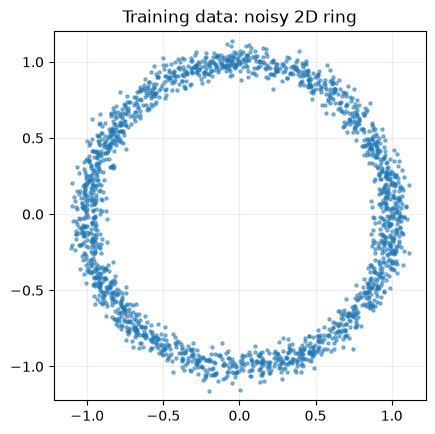

batch shape: torch.Size([32, 2])


In [2]:
def sample_data(batch_size, device=device):
    theta = 2 * math.pi * torch.rand(batch_size, device=device)
    x = torch.stack([torch.cos(theta), torch.sin(theta)], dim=-1)
    return x + 0.05 * torch.randn_like(x)

real = sample_data(2000).cpu().numpy()
plt.figure(figsize=(4.8, 4.8))
plt.scatter(real[:, 0], real[:, 1], s=5, alpha=0.5)
plt.title("Training data: noisy 2D ring")
plt.axis("equal"); plt.grid(alpha=0.2); plt.show()
print("batch shape:", sample_data(32).shape)

## 3. 定义前向扩散过程

使用原实验的 $T=100$ 和线性噪声调度：

$$
\beta_t\in[10^{-4},0.02],\quad\alpha_t=1-\beta_t,\quad\bar\alpha_t=\prod_{s=1}^{t}\alpha_s.
$$

直接采样任意时间步（不需要逐步执行前向扩散）：

$$
\mathbf x_t=\sqrt{\bar\alpha_t}\mathbf x_0+\sqrt{1-\bar\alpha_t}\boldsymbol\epsilon,\qquad\boldsymbol\epsilon\sim\mathcal N(0,I).
$$

**代码下标约定**：`t=0` 表示数学公式中的第 1 个扩散步（而非完全无噪声的 $x_0$ ）。

**末端分布检查**：当前短链配置下， $\bar\alpha_T\approx 0.364$ ，末端仍含原始信号，不能视为已经完全变成标准高斯。采样用 $\mathcal N(0,I)$ 初始化是一项近似，会带来末端分布不匹配。保留此配置用于观察机制；使用相同线性端点并取 `T=1000` 时， $\bar\alpha_T\approx4.04\times10^{-5}$ ，初始先验更接近前向末端。修改 `T` 后需从噪声调度开始重新运行、训练并比较生成结果。参见 [DDPM 原论文](https://arxiv.org/abs/2006.11239)。

### 3.1 从单步加噪推导直接采样公式

数学时间步为 $t=1,\ldots,T$ ， $\beta_t\in(0,1)$ ， $\alpha_t=1-\beta_t$ ， $\bar\alpha_0=1$ 。对本实验的二维样本， $I$ 是 $2\times2$ 单位矩阵。单步加噪为：

$$
x_t=\sqrt{\alpha_t}x_{t-1}+\sqrt{\beta_t}\epsilon_t,\qquad
\epsilon_t\sim\mathcal N(0,I).
$$

各步噪声彼此独立，并独立于 $x_0$ 。系数取平方根，是因为 $\mathrm{Cov}(cX)=c^2\mathrm{Cov}(X)$ ，所以噪声协方差是 $\beta_tI$ 。 $\alpha_t+\beta_t=1$ 还使单位协方差在单步更新下保持不变；它不会自动把圆环数据归一化为单位协方差。

展开两步：

$$
\begin{aligned}
x_2
&=\sqrt{\alpha_2}\left(\sqrt{\alpha_1}x_0+\sqrt{\beta_1}\epsilon_1\right)
+\sqrt{\beta_2}\epsilon_2\\
&=\sqrt{\alpha_1\alpha_2}x_0
+\sqrt{\alpha_2\beta_1}\epsilon_1+\sqrt{\beta_2}\epsilon_2.
\end{aligned}
$$

给定 $x_0$ 后，两项独立高斯噪声的协方差相加：

$$
\alpha_2\beta_1+\beta_2=1-\alpha_1\alpha_2.
$$

对更多步骤递推，得到：

$$
q(x_t\mid x_0)=\mathcal N\left(\sqrt{\bar\alpha_t}x_0,(1-\bar\alpha_t)I\right),
\qquad \bar\alpha_t=\prod_{s=1}^{t}\alpha_s.
$$

因此 `q_sample` 可以用一份新的标准高斯噪声直接采样指定 $t$ 的条件边际。`torch.cumprod` 计算累计乘积；代码 `t=k` 对应数学时间步 $k+1$ 。分别独立采样多个时刻，并不等于得到同一条前向链的轨迹。参见 [DDPM 公式 (2)、(4)](https://arxiv.org/abs/2006.11239)。


Terminal alpha_bar: 0.363563


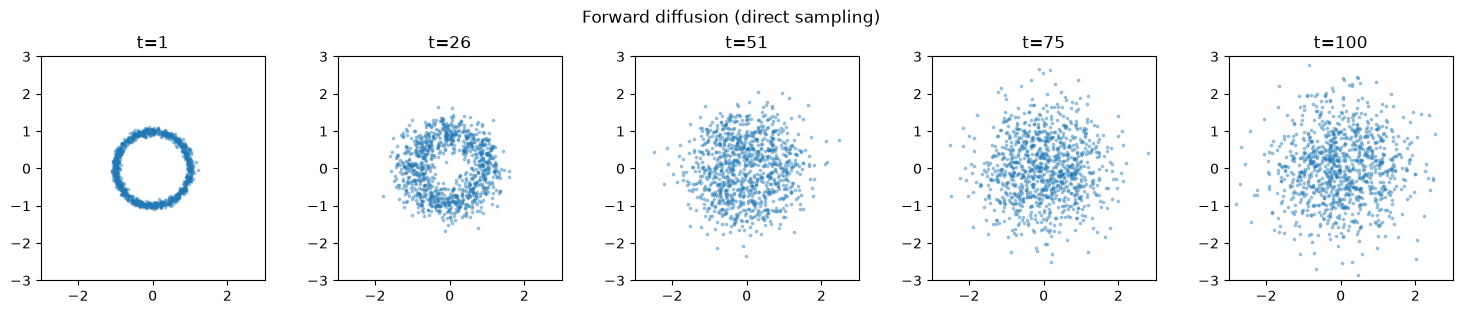

In [3]:
T = 100
beta = torch.linspace(1e-4, 0.02, T, device=device)
alpha = 1.0 - beta
alpha_bar = torch.cumprod(alpha, dim=0)
print(f"Terminal alpha_bar: {alpha_bar[-1].item():.6f}")

def q_sample(x0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x0)
    scale_x = alpha_bar[t].sqrt().unsqueeze(-1)
    scale_noise = (1.0 - alpha_bar[t]).sqrt().unsqueeze(-1)
    return scale_x * x0 + scale_noise * noise

x0 = sample_data(1000)
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, t_value in zip(axes, torch.linspace(0, T - 1, 5).round().long().tolist()):
    xt = q_sample(x0, torch.full((len(x0),), t_value, device=device, dtype=torch.long))
    points = xt.cpu().numpy()
    ax.scatter(points[:, 0], points[:, 1], s=3, alpha=0.35)
    ax.set(title=f"t={t_value+1}", xlim=(-3, 3), ylim=(-3, 3), aspect="equal")
plt.suptitle("Forward diffusion (direct sampling)"); plt.tight_layout(); plt.show()

## 4. 从零实现噪声预测网络

输入：带噪二维点 $\mathbf x_t\in\mathbb R^2$ 与归一化时间标量 $t/T$ 。输出：预测噪声 $\epsilon_\theta(\mathbf x_t,t)\in\mathbb R^2$ 。

第一版故意用最简单的 MLP：`[x, y, t/T] → 128 → 128 → [epsilon_x, epsilon_y]`，以便理解 DDPM 而不是网络架构。


In [4]:
class NoisePredictor(nn.Module):
    def __init__(self, hidden_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, 2),
        )

    def forward(self, x_t, t):
        t_normalized = t.float().unsqueeze(-1) / T
        return self.net(torch.cat([x_t, t_normalized], dim=-1))

model = NoisePredictor().to(device)
print(model)
print("output shape:", model(torch.randn(8, 2, device=device), torch.randint(T, (8,), device=device)).shape)

NoisePredictor(
  (net): Sequential(
    (0): Linear(in_features=3, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)
output shape: torch.Size([8, 2])


## 5. 训练：预测注入的高斯噪声

随机选取每个样本的时间步，构造 $\mathbf x_t$ ，最小化

$$
\mathcal L=\mathbb E_{\mathbf x_0,t,\epsilon}\big[\lVert\epsilon-\epsilon_\theta(\mathbf x_t,t)\rVert_2^2\big].
$$

原理演示默认训练 3000 步；若希望 CPU 更快完成，可改为 800–1500 步。这里使用 Adam 和 MSE。

### 5.1 预测噪声如何得到干净样本的估计？

训练时先抽取 $x_0,t,\epsilon$ ，再合成 $x_t$ ，因此监督噪声 $\epsilon$ 已知。由前向公式移项，将噪声替换为网络预测：

$$
\hat x_0(x_t,t)=
\frac{x_t-\sqrt{1-\bar\alpha_t}\epsilon_\theta(x_t,t)}
{\sqrt{\bar\alpha_t}}.
$$

这是一种参数化：预测噪声可以转换成对 $x_0$ 的估计，但不保证精确恢复生成 $x_t$ 的那个样本。MSE 的总体最优预测是给定 $(x_t,t)$ 的条件平均噪声。 $\hat x_0$ 也不是下一步的 $x_{t-1}$ ，反向采样还需构造相应的均值和方差。

本 Notebook 均匀抽取时间步，使用不带时间权重的噪声 MSE。它与 ELBO 的关系及成立条件见 [高斯混合实验 §6](02_2D_Gaussian_Mixture.ipynb)，不能直接把此 loss 视为完整最大似然目标。


step   600/3000 | loss 0.4868


step  1200/3000 | loss 0.4549


step  1800/3000 | loss 0.5479


step  2400/3000 | loss 0.4972


step  3000/3000 | loss 0.5008


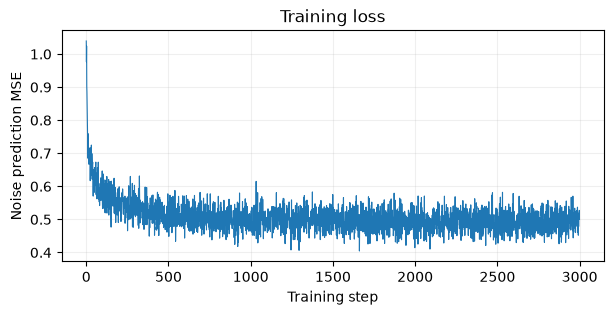

In [5]:
TRAIN_STEPS = 3000        # Colab CPU 可先改为 1000
BATCH_SIZE = 512
LEARNING_RATE = 1e-3
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
loss_history = []
model.train()
for step in range(TRAIN_STEPS):
    x0 = sample_data(BATCH_SIZE)
    t = torch.randint(0, T, (BATCH_SIZE,), device=device)
    noise = torch.randn_like(x0)
    x_t = q_sample(x0, t, noise)
    prediction = model(x_t, t)
    loss = torch.nn.functional.mse_loss(prediction, noise)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())
    if (step + 1) % max(1, TRAIN_STEPS // 5) == 0:
        print(f"step {step + 1:5d}/{TRAIN_STEPS} | loss {loss.item():.4f}")

plt.figure(figsize=(7, 3))
plt.plot(loss_history, linewidth=0.8)
plt.xlabel("Training step"); plt.ylabel("Noise prediction MSE")
plt.title("Training loss"); plt.grid(alpha=0.2); plt.show()

## 6. 反向采样：从高斯噪声恢复圆环

采用 DDPM 常见的反向更新式：

$$
\mu_\theta(\mathbf x_t,t)=\frac{1}{\sqrt{\alpha_t}}\left(\mathbf x_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\epsilon_\theta(\mathbf x_t,t)\right).
$$

对 $t\geq2$ 加入方差为 $\beta_t$ 的随机噪声；最后一步不添加。**这是简化的 fixed-large variance 选择**，第二个实验会使用另一种固定选择 posterior variance。后者是已知干净样本时的前向条件后验方差，并不意味着学到的反向模型一定更准确。

### 6.1 从条件后验均值到噪声参数化

给定 $x_t$ 和真实 $x_0$ ，前向链的条件后验 $q(x_{t-1}\mid x_t,x_0)$ 在 $t\geq2$ 时为高斯，其均值是：

$$
\tilde\mu_t(x_t,x_0)=
\frac{\sqrt{\bar\alpha_{t-1}}\beta_t}{1-\bar\alpha_t}x_0
+\frac{\sqrt{\alpha_t}(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}x_t.
$$

把上一节的 $\hat x_0$ 代入，利用 $\bar\alpha_t=\alpha_t\bar\alpha_{t-1}$ 合并 $x_t$ 的系数：

$$
\frac{\beta_t}{\sqrt{\alpha_t}(1-\bar\alpha_t)}
+\frac{\sqrt{\alpha_t}(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}
=\frac{1}{\sqrt{\alpha_t}}.
$$

噪声预测项的系数为 $-\beta_t/\sqrt{\alpha_t(1-\bar\alpha_t)}$ ，所以：

$$
\mu_\theta(x_t,t)=\tilde\mu_t(x_t,\hat x_0)
=\frac{1}{\sqrt{\alpha_t}}
\left(x_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\epsilon_\theta(x_t,t)\right).
$$

这解释了代码中的缩放和噪声校正：目标是生成前一步 $x_{t-1}$ ，不是只从 $x_t$ 中减去一份噪声。生成时真实 $x_0$ 未知，代入估计值也不保证恢复了真实反向条件分布。

对 $t\geq2$ ，本例按 $x_{t-1}=\mu_\theta+\sqrt{\beta_t}z$ 更新， $z\sim\mathcal N(0,I)$ 。数学 $t=1$ 时，已知 $x_0$ 的后验退化在 $x_0$ ；均值公式仍可延拓，而代码最终只输出 $\mu_\theta(x_1,1)$ ，不添加新噪声。后验配方见 [下一实验 §3](02_2D_Gaussian_Mixture.ipynb)，参数化对应 [DDPM 公式 (7)、(11)](https://arxiv.org/abs/2006.11239)。


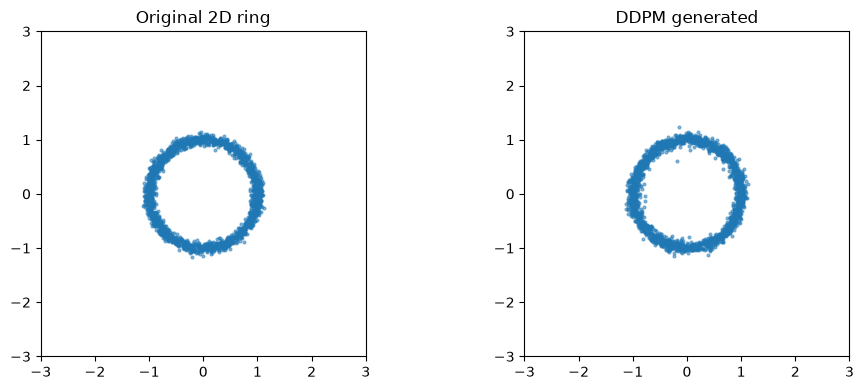

In [6]:
@torch.no_grad()
def sample_ddpm(n_samples=2000, capture_steps=None):
    model.eval()
    if capture_steps is None:
        capture_steps = {round((T - 1) * f) for f in (1, .8, .6, .4, .2, 0)}
    x = torch.randn(n_samples, 2, device=device)
    snapshots = {"initial noise": x.cpu().numpy().copy()}
    for step in reversed(range(T)):
        t = torch.full((n_samples,), step, device=device, dtype=torch.long)
        noise_pred = model(x, t)
        mean = (x - beta[step] / torch.sqrt(1-alpha_bar[step]) * noise_pred) / torch.sqrt(alpha[step])
        if step > 0:
            x = mean + torch.sqrt(beta[step]) * torch.randn_like(x)
        else:
            x = mean
        if step in capture_steps:
            snapshots[f"t={step}"] = x.cpu().numpy().copy()
    return x.cpu().numpy(), snapshots

generated, snapshots = sample_ddpm()
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, points, name in zip(axes, [real, generated], ["Original 2D ring", "DDPM generated"]):
    ax.scatter(points[:, 0], points[:, 1], s=4, alpha=0.5)
    ax.set(title=name, xlim=(-3, 3), ylim=(-3, 3), aspect="equal")
plt.tight_layout(); plt.show()

## 7. 可视化逐步反向去噪
观察从随机二维高斯点云，逐渐凝聚到圆环的过程。注意：**每张图显示的是所有粒子的分布，不是一个二维粒子的运动轨迹。**


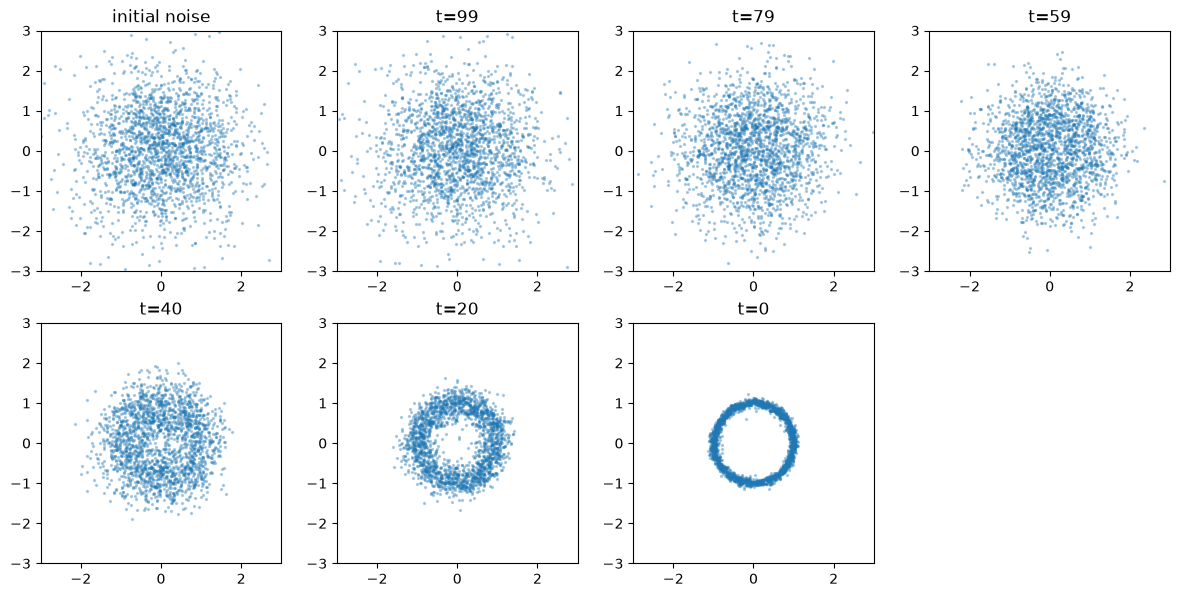

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, (label, points) in zip(axes.flat, snapshots.items()):
    ax.scatter(points[:, 0], points[:, 1], s=2, alpha=0.3)
    ax.set(title=label, xlim=(-3, 3), ylim=(-3, 3), aspect="equal")
for ax in axes.flat[len(snapshots):]: ax.axis("off")
plt.tight_layout(); plt.show()

## 8. 动手实验与知识检查

1. 将 `T` 改为 50 / 200，并**重新从噪声调度开始运行**：扩散速度有何变化？
2. 将训练数据的 `0.05` 改为 `0.2`：模型生成的圆环厚度如何变化？
3. 将 `TRAIN_STEPS` 改为 300、1000、3000：训练不足时会发生什么？
4. 想一想：为什么训练时可以直接采样任意 $x_t$ ，但生成时要从最后一个时间步反向迭代？

**通往机器人策略**：现在生成的是 $x\in\mathbb R^2$ ；之后可以把每个样本替换成一段 $A\in\mathbb R^{H\times d_a}$ 的动作序列。训练与逆向采样框架仍可复用。
